In [ ]:
# Customer Personality Analysis - Unsupervised Learning Tugas 3


import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns

# Step 1: Load dataset

In [ ]:
# Membaca file cpa.csv yang sudah di upload ke session storage Colab
df = pd.read_csv('cpa.csv', sep='\t')

# Menampilkan 5 baris pertama untuk memastikan data terbaca dengan rapi
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0


#Step2: lakukan Eksplorasi awal

In [ ]:
# Melihat struktur dan tipe data
print("--- Struktur dan Tipe Data ---")
df.info()

# Melihat jumlah missing value pada tiap kolom
print("\n--- Jumlah Missing Value ---")
print(df.isnull().sum())

# Melihat distribusi fitur utama (statistik deskriptif)
print("\n--- Distribusi Fitur ---")
display(df.describe(include='all'))

--- Struktur dan Tipe Data ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   object 
 3   Marital_Status       2240 non-null   object 
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   object 
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDeal

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
count,2240.000000,2240.000000,2240,2240,2216.000000,2240.000000,2240.000000,2240,2240.000000,2240.000000,...,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.0,2240.0,2240.000000
unique,NaN,NaN,5,8,NaN,NaN,NaN,663,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,NaN,Graduation,Married,NaN,NaN,NaN,31-08-2012,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,NaN,1127,864,NaN,NaN,NaN,12,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,5592.159821,1968.805804,NaN,NaN,52247.251354,0.444196,0.506250,NaN,49.109375,303.935714,...,5.316518,0.072768,0.074554,0.072768,0.064286,0.013393,0.009375,3.0,11.0,0.149107
std,3246.662198,11.984069,NaN,NaN,25173.076661,0.538398,0.544538,NaN,28.962453,336.597393,...,2.426645,0.259813,0.262728,0.259813,0.245316,0.114976,0.096391,0.0,0.0,0.356274
min,0.000000,1893.000000,NaN,NaN,1730.000000,0.000000,0.000000,NaN,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
25%,2828.250000,1959.000000,NaN,NaN,35303.000000,0.000000,0.000000,NaN,24.000000,23.750000,...,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
50%,5458.500000,1970.000000,NaN,NaN,51381.500000,0.000000,0.000000,NaN,49.000000,173.500000,...,6.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
75%,8427.750000,1977.000000,NaN,NaN,68522.000000,1.000000,1.000000,NaN,74.000000,504.250000,...,7.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000


# Step 3: Identifikasi kolom numerik & kategori

In [ ]:
# Memisahkan kolom menjadi tipe numerik (int/float) dan kategori (object)
num_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()

# Menampilkan hasil identifikasi isi masing-masing kelompok
print("Jumlah Kolom Numerik:", len(num_cols))
print("Daftar Kolom Numerik:\n", num_cols)

print("\nJumlah Kolom Kategori:", len(cat_cols))
print("Daftar Kolom Kategori:\n", cat_cols)

Jumlah Kolom Numerik: 26
Daftar Kolom Numerik:
 ['ID', 'Year_Birth', 'Income', 'Kidhome', 'Teenhome', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1', 'AcceptedCmp2', 'Complain', 'Z_CostContact', 'Z_Revenue', 'Response']

Jumlah Kolom Kategori: 3
Daftar Kolom Kategori:
 ['Education', 'Marital_Status', 'Dt_Customer']


# Step 4: Imputasi missing value

In [ ]:
from sklearn.impute import SimpleImputer
import pandas as pd

#Menangani kolom numerik (termasuk 24 missing value di kolom 'Income')
#Kita akan menggunakan teknik 'median' (nilai tengah)
num_imputer = SimpleImputer(strategy='median')
df_num = pd.DataFrame(num_imputer.fit_transform(df[num_cols]), columns=num_cols)

#Menangani kolom kategori
#Kita  akan menggunakan teknik 'most_frequent' (modus/paling sering muncul)
cat_imputer = SimpleImputer(strategy='most_frequent')
df_cat = pd.DataFrame(cat_imputer.fit_transform(df[cat_cols]), columns=cat_cols)

#Pengecekan akhir untuk membuktikan missing value sudah hilang
print("Total missing value di fitur numerik sekarang:", df_num.isnull().sum().sum())
print("Total missing value di fitur kategori sekarang:", df_cat.isnull().sum().sum())

Total missing value di fitur numerik sekarang: 0
Total missing value di fitur kategori sekarang: 0



# Step 5: Encoding fitur kategori

In [ ]:
from sklearn.preprocessing import OneHotEncoder
import pandas as pd

#Menerapkan One-Hot Encoding pada fitur kategori
#Parameter drop='first' untuk mencegah masalah multikolinearitas (dummy variable trap)
encoder = OneHotEncoder(sparse_output=False, drop='first')

#Melakukan transformasi teks menjadi angka biner (0 dan 1)
encoded_data = encoder.fit_transform(df_cat)

#Mengembalikan formatnya menjadi DataFrame agar rapi, lengkap dengan nama kolom barunya
df_cat_encoded = pd.DataFrame(encoded_data, columns=encoder.get_feature_names_out(df_cat.columns))

print("Jumlah kolom kategori setelah di-encode:", df_cat_encoded.shape[1])
display(df_cat_encoded.head())

Jumlah kolom kategori setelah di-encode: 673


,Education_Basic,Education_Graduation,Education_Master,Education_PhD,Marital_Status_Alone,Marital_Status_Divorced,Marital_Status_Married,Marital_Status_Single,Marital_Status_Together,Marital_Status_Widow,...,Dt_Customer_31-03-2014,Dt_Customer_31-05-2013,Dt_Customer_31-05-2014,Dt_Customer_31-07-2012,Dt_Customer_31-07-2013,Dt_Customer_31-08-2012,Dt_Customer_31-08-2013,Dt_Customer_31-10-2012,Dt_Customer_31-12-2012,Dt_Customer_31-12-2013
0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


#Gabungkan data numerik & hasil encoding

In [ ]:
#Menggabungkan df_num (numerik dari Step 4) dan df_cat_encoded (kategori dari Step 5) menyamping (axis=1)
df_processed = pd.concat([df_num, df_cat_encoded], axis=1)

print("Dimensi total data pelanggan sekarang:", df_processed.shape)
display(df_processed.head())

Dimensi total data pelanggan sekarang: (2240, 699)


,ID,Year_Birth,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,...,Dt_Customer_31-03-2014,Dt_Customer_31-05-2013,Dt_Customer_31-05-2014,Dt_Customer_31-07-2012,Dt_Customer_31-07-2013,Dt_Customer_31-08-2012,Dt_Customer_31-08-2013,Dt_Customer_31-10-2012,Dt_Customer_31-12-2012,Dt_Customer_31-12-2013
0,5524.0,1957.0,58138.0,0.0,0.0,58.0,635.0,88.0,546.0,172.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,2174.0,1954.0,46344.0,1.0,1.0,38.0,11.0,1.0,6.0,2.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,4141.0,1965.0,71613.0,0.0,0.0,26.0,426.0,49.0,127.0,111.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,6182.0,1984.0,26646.0,1.0,0.0,26.0,11.0,4.0,20.0,10.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,5324.0,1981.0,58293.0,1.0,0.0,94.0,173.0,43.0,118.0,46.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


# Step 6: Scaling data

In [ ]:
from sklearn.preprocessing import StandardScaler
import pandas as pd

# Inisialisasi fungsi standarisasi (membuat rata-rata jadi 0 dan standar deviasi jadi 1)
scaler = StandardScaler()

# Menerapkan scaling ke seluruh data yang sudah digabung (df_processed)
scaled_data = scaler.fit_transform(df_processed)

# Mengubah kembali menjadi DataFrame agar mudah dibaca
df_scaled = pd.DataFrame(scaled_data, columns=df_processed.columns)

print("Dimensi data setelah di-scaling:", df_scaled.shape)
display(df_scaled.head())

Dimensi data setelah di-scaling: (2240, 699)


,ID,Year_Birth,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,...,Dt_Customer_31-03-2014,Dt_Customer_31-05-2013,Dt_Customer_31-05-2014,Dt_Customer_31-07-2012,Dt_Customer_31-07-2013,Dt_Customer_31-08-2012,Dt_Customer_31-08-2013,Dt_Customer_31-10-2012,Dt_Customer_31-12-2012,Dt_Customer_31-12-2013
0,-0.020999,-0.985345,0.235696,-0.825218,-0.929894,0.307039,0.983781,1.551577,1.679702,2.462147,...,-0.047298,-0.036621,-0.029894,-0.021134,-0.029894,-0.073389,-0.059868,-0.047298,-0.021134,-0.036621
1,-1.053058,-1.235733,-0.235454,1.032559,0.906934,-0.383664,-0.870479,-0.636301,-0.713225,-0.650449,...,-0.047298,-0.036621,-0.029894,-0.021134,-0.029894,-0.073389,-0.059868,-0.047298,-0.021134,-0.036621
2,-0.447070,-0.317643,0.773999,-0.825218,-0.929894,-0.798086,0.362723,0.570804,-0.177032,1.345274,...,-0.047298,-0.036621,-0.029894,-0.021134,-0.029894,-0.073389,-0.059868,-0.047298,-0.021134,-0.036621
3,0.181716,1.268149,-1.022355,1.032559,-0.929894,-0.798086,-0.870479,-0.560857,-0.651187,-0.503974,...,-0.047298,-0.036621,-0.029894,-0.021134,-0.029894,-0.073389,-0.059868,-0.047298,-0.021134,-0.036621
4,-0.082614,1.017761,0.241888,1.032559,-0.929894,1.550305,-0.389085,0.419916,-0.216914,0.155164,...,-0.047298,-0.036621,-0.029894,-0.021134,-0.029894,-0.073389,-0.059868,-0.047298,-0.021134,-0.036621



# Step 7: Tentukan jumlah cluster optimal (Elbow + Silhouette)

Grafik Elbow & Silhouette


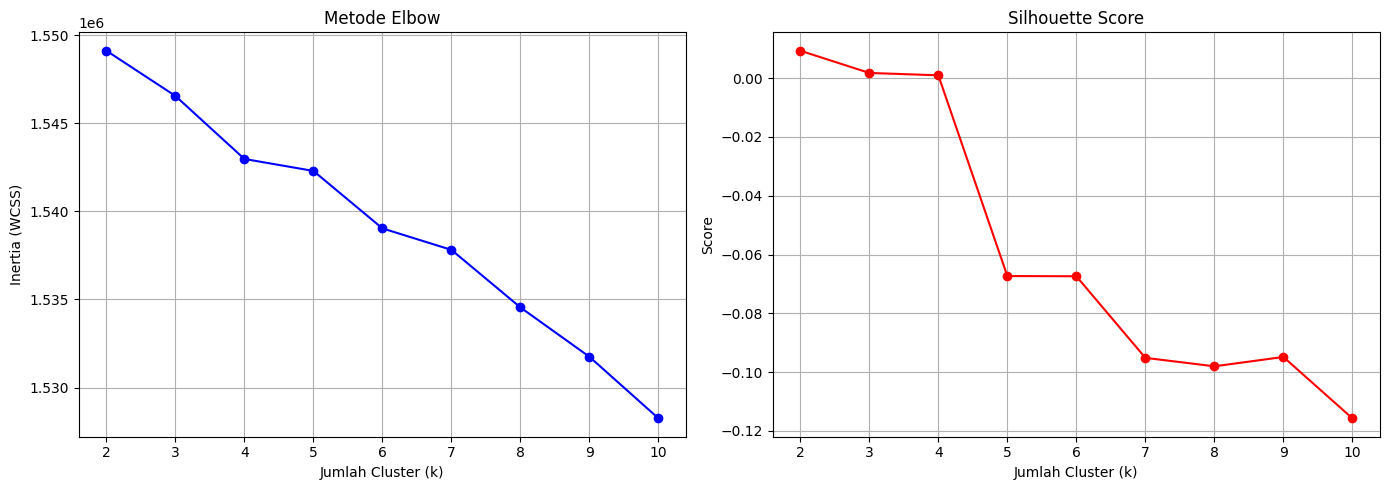

In [80]:
%matplotlib inline

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

# Menyiapkan tempat penampungan nilai untuk grafik
wcss = []
silhouette_scores = []

# Membagi pelanggan menjadi 2 sampai 10 klaster
K = range(2, 11)

print("Grafik Elbow & Silhouette")

for k in K:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(df_scaled)

    wcss.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(df_scaled, kmeans.labels_))

# Membuat visualisasi 2 grafik bersebelahan
plt.figure(figsize=(14, 5))

# Grafik 1: Elbow Method
plt.subplot(1, 2, 1)
plt.plot(K, wcss, marker='o', linestyle='-', color='blue')
plt.title('Metode Elbow')
plt.xlabel('Jumlah Cluster (k)')
plt.ylabel('Inertia (WCSS)')
plt.grid(True)

# Grafik 2: Silhouette Score
plt.subplot(1, 2, 2)
plt.plot(K, silhouette_scores, marker='o', linestyle='-', color='red')
plt.title('Silhouette Score')
plt.xlabel('Jumlah Cluster (k)')
plt.ylabel('Score')
plt.grid(True)

plt.tight_layout()
plt.show()

# Step 8: Pilih k optimal dan klasterisasi

In [ ]:
from sklearn.cluster import KMeans

# Menetapkan jumlah klaster optimal berdasarkan analisis Silhouette Score (k = 2)
k_optimal = 2

# Inisialisasi model K-Means standar
kmeans = KMeans(n_clusters=k_optimal, random_state=42, n_init=10)

# Melatih model dan memprediksi klaster untuk setiap baris data pelanggan
cluster_labels = kmeans.fit_predict(df_scaled)

# Menambahkan hasil label klaster (0 atau 1) ke dalam dataframe asli dan dataframe terproses
df['Cluster'] = cluster_labels
df_processed['Cluster'] = cluster_labels

# Menampilkan informasi ringkas jumlah anggota di tiap klaster
print("=== DISTRIBUSI JUMLAH PELANGGAN PER KLASTER ===")
print(df['Cluster'].value_counts())

# Menampilkan preview beberapa baris data teratas beserta nomor klasternya
display(df[['ID', 'Income', 'Cluster']].head())

=== DISTRIBUSI JUMLAH PELANGGAN PER KLASTER ===
Cluster
1    1259
0     981
Name: count, dtype: int64


,ID,Income,Cluster
0,5524,58138.0,0
1,2174,46344.0,1
2,4141,71613.0,0
3,6182,26646.0,1
4,5324,58293.0,1


# Step 9: Visualisasi klaster dengan PCA 2D

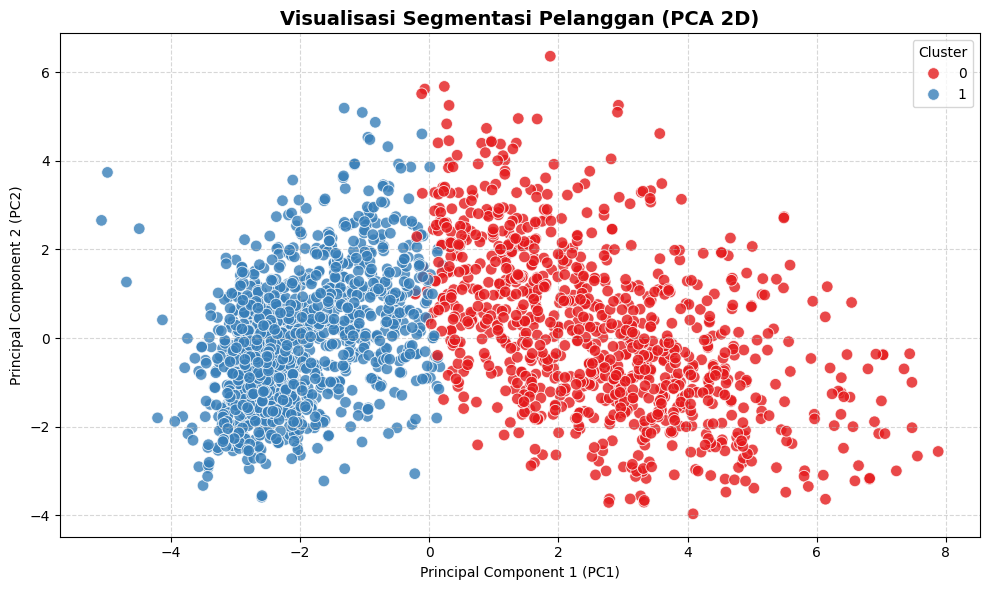

In [ ]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns

# Mereduksi dimensi data yang sangat banyak (699 kolom) menjadi hanya 2 dimensi utama (PCA)
pca = PCA(n_components=2)
pca_features = pca.fit_transform(df_scaled)

# Membuat DataFrame khusus untuk hasil PCA agar mudah di-plot
df_pca = pd.DataFrame(pca_features, columns=['PC1', 'PC2'])
df_pca['Cluster'] = df['Cluster'].values

# Membuat visualisasi Scatterplot 2D
plt.figure(figsize=(10, 6))
sns.scatterplot(
    x='PC1',
    y='PC2',
    hue='Cluster',
    data=df_pca,
    palette='Set1',
    s=70,
    alpha=0.8
)

plt.title('Visualisasi Segmentasi Pelanggan (PCA 2D)', fontsize=14, fontweight='bold')
plt.xlabel('Principal Component 1 (PC1)')
plt.ylabel('Principal Component 2 (PC2)')
plt.legend(title='Cluster')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# Step 10: Profiling cluster (rata-rata fitur per cluster)

In [ ]:
# Menganalisis karakteristik rata-rata dari fitur numerik asli berdasarkan klaster
cluster_profile = df.groupby('Cluster')[num_cols].mean()

# Menampilkan tabel hasil profiling
print("=== TABEL PROFILING RATA-RATA KLUSTER ===")
display(cluster_profile.T)

=== TABEL PROFILING RATA-RATA KLUSTER ===


Cluster,0,1
ID,5545.694190,5628.365369
Year_Birth,1966.864424,1970.318507
Income,70894.868448,37650.202735
Kidhome,0.078491,0.729150
Teenhome,0.469929,0.534551
Recency,49.332314,48.935663
MntWines,588.738022,82.020651
MntFruits,52.329256,6.022240
MntMeatProducts,338.510703,33.271644
MntFishProducts,74.258919,8.903098


# Simpulkan Analisa dari hasil

Berdasarkan hasil pemodelan Unsupervised Learning menggunakan algoritma **K-Means Clustering ($k=2$)** dan visualisasi reduksi dimensi **PCA 2D**, pelanggan perusahaan berhasil dikelompokkan ke dalam 2 segmen utama dengan karakteristik yang sangat berbeda:

**1. Klaster 0: Segmen Pelanggan Premium / High-Value Spenders**



*   **Karakteristik Utama:** Memiliki rata-rata pendapatan (Income) yang jauh lebih tinggi (sekitar 70.894) dibandingkan klaster lainnya.
*   **Perilaku Pembelian:** Menunjukkan tingkat pembelian produk premium yang sangat tinggi, terutama pada kategori Wine (MntWines rata-rata ~588) dan produk daging (MntMeatProducts rata-rata ~338). Mereka juga lebih aktif melakukan transaksi melalui berbagai jalur pembelian (web, katalog, dan toko fisik).

*   **Strategi Bisnis:** Kelompok ini merupakan aset utama perusahaan. Layak diberikan program loyalty/membership eksklusif, penawaran produk premium terbatas (upselling), serta pelayanan personal.


**2. Klaster 1: Segmen Pelanggan Berkembang / Budget-Conscious**



*   **Karakteristik Utama:** Memiliki rata-rata pendapatan (Income) yang lebih rendah (sekitar 37.650).
*   **Perilaku Pembelian:** Memiliki tingkat pengeluaran dan volume pembelian produk yang jauh lebih rendah di semua kategori (misalnya MntWines rata-rata hanya ~82 dan MntMeatProducts ~33).

*   **Strategi Bisnis:** Kelompok ini lebih sensitif terhadap harga (price-sensitive). Strategi pemasaran yang cocok adalah promosi diskon, bundling produk hemat, atau penawaran cashback untuk mendorong frekuensi belanja mereka.


